# 01 — EDA and Random Forest on Breast Cancer Wisconsin

This notebook walks through:

1. **Load the data** and fix the label convention: `1 = malignant` (the class explained throughout the seminar).
2. **Short EDA**: class balance, feature scales, per-class distributions, feature correlations.
3. **Train/test split** (80/20, stratified, fixed seed).
4. **Train a Random Forest** and report accuracy and ROC-AUC (cross-validation on train + evaluation on test).
5. **Save the model and the split** so the later LIME/SHAP notebooks reuse exactly the same setup.

Data source: Wolberg, Street & Mangasarian (1995), *Breast Cancer Wisconsin (Diagnostic)*, UCI Machine Learning Repository; loaded via `sklearn.datasets.load_breast_cancer`.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split

SEED = 42
ARTIFACT_DIR = Path("artifacts")
CLASS_NAMES = ["benign", "malignant"]

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

## 1. Load the data

sklearn encodes `0 = malignant`, `1 = benign`. We **flip the labels** so that `1 = malignant`; predicted probabilities and attribution signs then read as "pushing towards malignant".

In [2]:
raw = load_breast_cancer(as_frame=True)
X = raw.data
y = (1 - raw.target).rename("malignant")

print(f"Samples: {X.shape[0]}, features: {X.shape[1]}")
print(f"Missing values: {X.isna().sum().sum()}")
print(y.value_counts().rename(index=dict(enumerate(CLASS_NAMES))))

Samples: 569, features: 30
Missing values: 0
malignant
benign       357
malignant    212
Name: count, dtype: int64


## 2. EDA

30 features = 10 cell-nucleus measurements × 3 versions: `mean`, `error` (standard error), `worst` (mean of the three largest values).

### 2.1. Class balance and feature scales

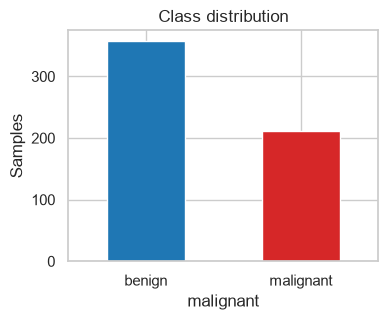

,mean,std,min,max
mean radius,14.127,3.524,6.981,28.110
mean texture,19.290,4.301,9.710,39.280
mean perimeter,91.969,24.299,43.790,188.500
mean area,654.889,351.914,143.500,2501.000
mean smoothness,0.096,0.014,0.053,0.163
mean compactness,0.104,0.053,0.019,0.345
mean concavity,0.089,0.080,0.000,0.427
mean concave points,0.049,0.039,0.000,0.201
mean symmetry,0.181,0.027,0.106,0.304
mean fractal dimension,0.063,0.007,0.050,0.097


In [3]:
fig, ax = plt.subplots(figsize=(4, 3))
y.map(dict(enumerate(CLASS_NAMES))).value_counts().plot.bar(ax=ax, color=["tab:blue", "tab:red"])
ax.set_title("Class distribution")
ax.set_ylabel("Samples")
plt.xticks(rotation=0)
plt.show()

mean_features = [c for c in X.columns if c.startswith("mean ")]
X[mean_features].describe().T[["mean", "std", "min", "max"]]

### 2.2. Per-class distributions

Four representative features: size (`radius`), texture (`texture`), shape (`concave points`) and smoothness (`smoothness`).

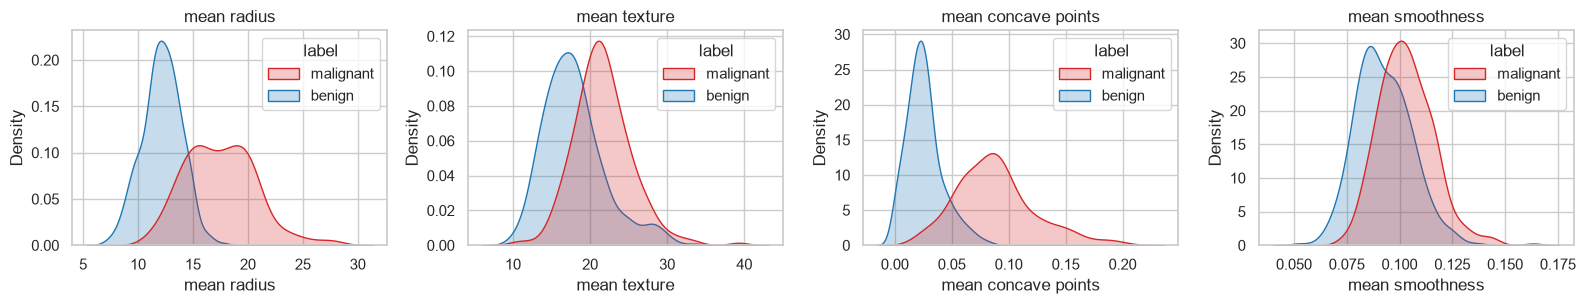

In [4]:
selected = ["mean radius", "mean texture", "mean concave points", "mean smoothness"]
plot_df = X[selected].assign(label=y.map(dict(enumerate(CLASS_NAMES))))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, feature in zip(axes, selected):
    sns.kdeplot(data=plot_df, x=feature, hue="label", fill=True, common_norm=False,
                palette={"benign": "tab:blue", "malignant": "tab:red"}, ax=ax)
    ax.set_title(feature)
plt.tight_layout()
plt.show()

### 2.3. Feature correlations

This matters for the seminar: strongly correlated features let attributions be split or shifted arbitrarily between them, and SHAP under the independence assumption generates unrealistic samples.

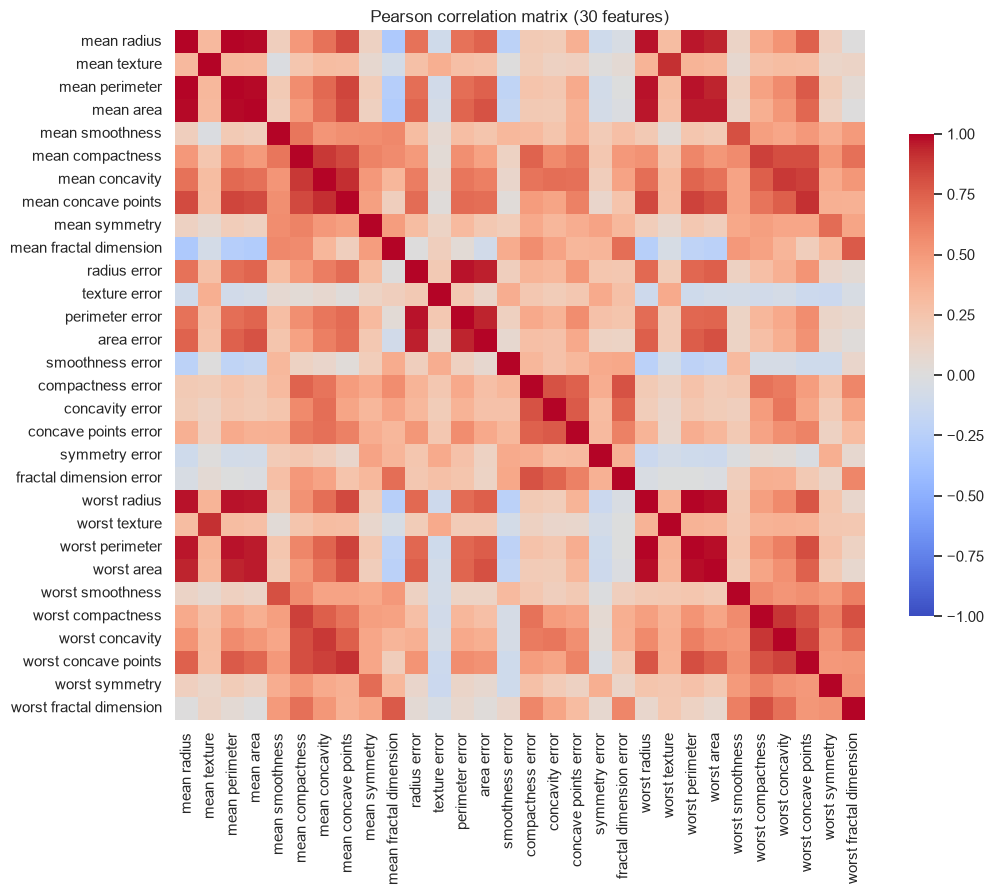

Feature pairs with |r| >= 0.95: 15


,,r
mean radius,mean perimeter,0.998
worst radius,worst perimeter,0.994
mean radius,mean area,0.987
mean perimeter,mean area,0.987
worst radius,worst area,0.984
worst perimeter,worst area,0.978
radius error,perimeter error,0.973
mean perimeter,worst perimeter,0.970
mean radius,worst radius,0.970
mean perimeter,worst radius,0.969


In [5]:
corr = X.corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Pearson correlation matrix (30 features)")
plt.tight_layout()
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
strong_pairs = upper[upper.abs() >= 0.95].sort_values(ascending=False)
print(f"Feature pairs with |r| >= 0.95: {len(strong_pairs)}")
strong_pairs.rename("r").to_frame()

**EDA takeaways**

- No missing values; moderate class imbalance (about 37% malignant), so ROC-AUC is reported alongside accuracy.
- Feature scales differ by orders of magnitude (`mean area` in the hundreds, `mean smoothness` around 0.1). Random Forest needs no scaling, but units matter when reading attributions.
- Size and shape features (`radius`, `concave points`) separate the classes well; `smoothness` overlaps more.
- The `radius`–`perimeter`–`area` group carries nearly identical information (|r| ≈ 0.99). It is the main candidate for an unstable explanation in later notebooks.

## 3. Train/test split

80/20, stratified by label to preserve the class ratio. The test set is used only once for final evaluation and for picking the instances to explain.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print(f"Train: {X_train.shape}, malignant = {y_train.mean():.1%}")
print(f"Test:  {X_test.shape}, malignant = {y_test.mean():.1%}")

Train: (455, 30), malignant = 37.4%
Test:  (114, 30), malignant = 36.8%


## 4. Random Forest

sklearn defaults with 500 trees, no tuning: the goal is a reasonably good black box to explain, not the best possible score.

### 4.1. 5-fold cross-validation on the training set

Shows the spread of the scores, so conclusions do not rest on a single split.

In [7]:
rf = RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=-1)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_scores = cross_validate(rf, X_train, y_train, cv=cv, scoring=["accuracy", "roc_auc"])

for metric in ["accuracy", "roc_auc"]:
    scores = cv_scores[f"test_{metric}"]
    print(f"CV {metric:<8}: {scores.mean():.4f} ± {scores.std():.4f}")

CV accuracy: 0.9626 ± 0.0204
CV roc_auc : 0.9879 ± 0.0073


### 4.2. Test-set evaluation

In [8]:
rf.fit(X_train, y_train)

proba_malignant = rf.predict_proba(X_test)[:, 1]
y_pred = rf.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)
test_roc_auc = roc_auc_score(y_test, proba_malignant)
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test ROC-AUC:  {test_roc_auc:.4f}\n")
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3))

Test accuracy: 0.9737
Test ROC-AUC:  0.9944

              precision    recall  f1-score   support

      benign      0.960     1.000     0.980        72
   malignant      1.000     0.929     0.963        42

    accuracy                          0.974       114
   macro avg      0.980     0.964     0.971       114
weighted avg      0.975     0.974     0.973       114



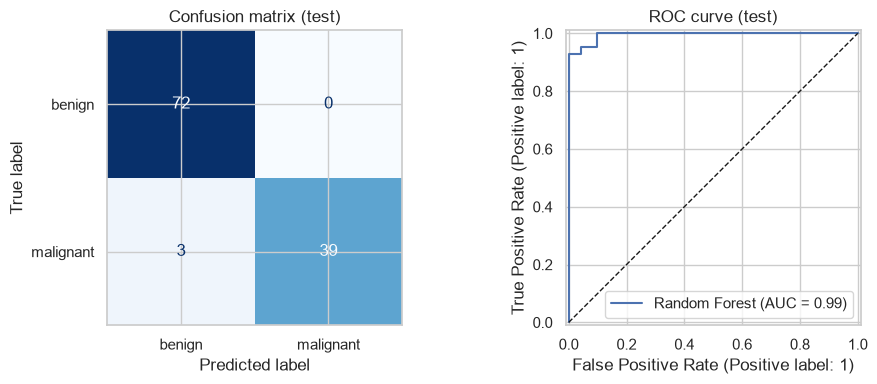

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=CLASS_NAMES, cmap="Blues", colorbar=False, ax=axes[0]
)
axes[0].set_title("Confusion matrix (test)")
RocCurveDisplay.from_predictions(y_test, proba_malignant, name="Random Forest", ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[1].set_title("ROC curve (test)")
plt.tight_layout()
plt.show()

## 5. Save the model and the split

The LIME/SHAP notebooks reload exactly this model and train/test split, so every comparison shares one setup.

In [10]:
ARTIFACT_DIR.mkdir(exist_ok=True)
joblib.dump(rf, ARTIFACT_DIR / "random_forest.joblib")
joblib.dump(
    {"X_train": X_train, "X_test": X_test, "y_train": y_train, "y_test": y_test,
     "class_names": CLASS_NAMES, "seed": SEED},
    ARTIFACT_DIR / "data_split.joblib",
)
print(f"Saved to {ARTIFACT_DIR.resolve()}")

Saved to D:\HCMUS_ComputerScience\Year3\CS420-AI\Seminar\Code\artifacts


## Summary

- The Random Forest reaches high accuracy and ROC-AUC on both cross-validation and the test set (see Section 4).
- This sets up the seminar's guiding question: the model is highly accurate, but is its explanation reliable?
- Next step: pick 3 test instances (confident, near the threshold, misclassified) and explain them with LIME and SHAP.